<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/%C3%B6dev4_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

'duvar.jpeg' bulunamadı, örnek görsel oluşturuluyor...


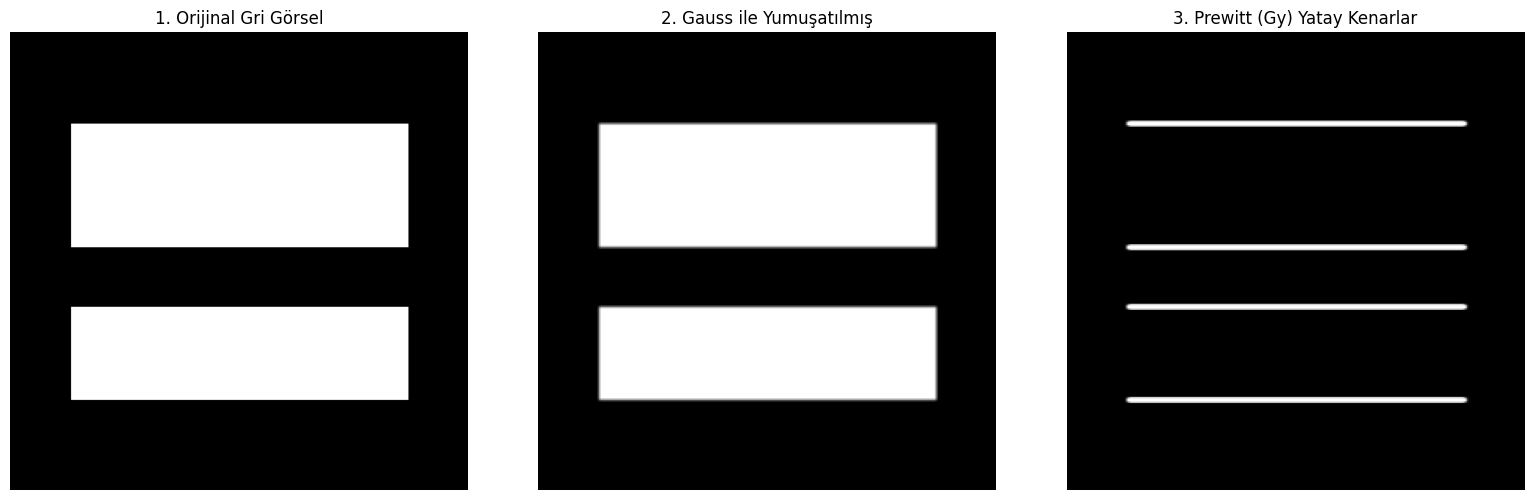

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Daha önce yüklediğiniz görseli gri tonlamalı oku
# (Dosya adını Colab'deki adıyla eşleştirin, örn: 'duvar.jpeg' veya 'test.jpg')
image_path = 'duvar.jpeg'
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Eğer görsel bulunamazsa test için otomatik bir görsel oluştur
if image is None:
    print(f"'{image_path}' bulunamadı, örnek görsel oluşturuluyor...")
    image = np.zeros((300, 300), dtype=np.uint8)
    cv2.rectangle(image, (40, 60), (260, 140), 255, -1)
    cv2.rectangle(image, (40, 180), (260, 240), 255, -1)

# 2. Tuğla yüzeyindeki pürüzleri ve gürültüyü azaltmak için Gauss filtresi uygula
blurred_image = cv2.GaussianBlur(image, (3, 3), sigmaX=1.0)

# 3. 3x3 Prewitt Yatay Kenar Filtresi (Gy) Tanımı
prewitt_gy_kernel = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
], dtype=np.float32)

# 4. Konvolüsyon işlemini gerçekleştir (Negatif gradyanları korumak için CV_64F kullanılır)
prewitt_gy_edges = cv2.filter2D(blurred_image, cv2.CV_64F, prewitt_gy_kernel)

# 5. Mutlak değeri al ve 8-bit (0-255) aralığına sınırla
abs_edges = np.absolute(prewitt_gy_edges)
output_image = np.uint8(np.clip(abs_edges, 0, 255))

# 6. Sonuçları görselleştir
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.title("1. Orijinal Gri Görsel", fontsize=12)
plt.imshow(image, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("2. Gauss ile Yumuşatılmış", fontsize=12)
plt.imshow(blurred_image, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("3. Prewitt (Gy) Yatay Kenarlar", fontsize=12)
plt.imshow(output_image, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
